In [1]:
import re
from collections import Counter
import matplotlib.pyplot as plt
from datasets import load_dataset

In [2]:
def preprocess_text(text):
    raw_sentences = re.split(r'[.!?]+', text)
    processed_sentences = []
    
    for sentence in raw_sentences:
        sentence = sentence.lower()
        sentence = re.sub(r"[^a-zA-Zа-яА-ЯабвгґдеєжзиіїйклмнопрстуфхцчшщьюяА-БВГҐДЕЄЖЗИІЇЙКЛМНОПРСТУФХЦЧШЩЬЮЯ\'’\`\-]", " ", sentence)
        sentence = re.sub(r"(?<!\w)[-\'’\`]|[-\'’\`](?!\w)", " ", sentence)
        
        words = sentence.split()
        words = [word for word in words if len(word) >= 3]
        
        if len(words) >= 5:
            processed_sentences.append(words)
            
    return processed_sentences

In [3]:
def build_wikipedia_corpus(target_sentence_count=300000):
    dataset = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)
    sentences = []
    
    for article in dataset:
        article_sentences = preprocess_text(article['text'])
        sentences.extend(article_sentences)
        
        if len(sentences) >= target_sentence_count:
            sentences = sentences[:target_sentence_count]
            break
            
    return sentences

In [4]:
TARGET_COUNT = 300000
sentences = build_wikipedia_corpus(target_sentence_count=TARGET_COUNT)

sentences[:5]

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

c:\Users\myure\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\myure\.cache\huggingface\hub\datasets--wikimedia--wikipedia. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[['земле',
  'пис',
  'від',
  'опис',
  'землі',
  'земля',
  'писати',
  'описувати',
  'система',
  'наук',
  'вивчає',
  'географічну',
  'оболонку',
  'землі',
  'епігеосферу',
  'просторову',
  'природну',
  'соціально-економічну',
  'різноманітність',
  'господарство',
  'населення',
  'планети',
  'окремих',
  'регіонів',
  'країн',
  'також',
  "зв'язки",
  'між',
  'природним',
  'середовищем',
  'діяльністю',
  'людини'],
 ['сучасному',
  'розумінні',
  'поняття',
  'географія',
  'заміщено',
  'поняттям',
  'географічні',
  'науки'],
 ['поняття',
  'уперше',
  'термін',
  'географія',
  'був',
  'запропонований',
  'давньогрецьким',
  'географом',
  'ератосфеном'],
 ['структура',
  'основне',
  'завдання',
  'сучасної',
  'географії',
  'полягає',
  'вивченні',
  'законів',
  'закономірностей',
  'розміщення',
  'взаємодії',
  'компонентів',
  'географічного',
  'середовища',
  'їхніх',
  'поєднань',
  'різних',
  'рівнях'],
 ['складність',
  "об'єкта",
  'дослідження',
  '

In [5]:
total_sentences = len(sentences)
word_counter = Counter(word for sentence in sentences for word in sentence)
unique_words_count = len(word_counter)
top_20_words = word_counter.most_common(20)

print(f"Загальна кількість речень: {total_sentences}")
print(f"Кількість унікальних слів: {unique_words_count}")
print("\n20 найчастіших слів:")
for word, freq in top_20_words:
    print(f"{word}: {freq}")

Загальна кількість речень: 300000
Кількість унікальних слів: 328250

20 найчастіших слів:
року: 27149
від: 17028
також: 13172
для: 13137
його: 13092
україни: 12580
про: 12047
під: 9915
році: 9131
було: 9089
району: 7870
був: 7822
він: 7517
після: 7481
які: 7131
або: 6814
населення: 6471
території: 6433
час: 6198
області: 6155


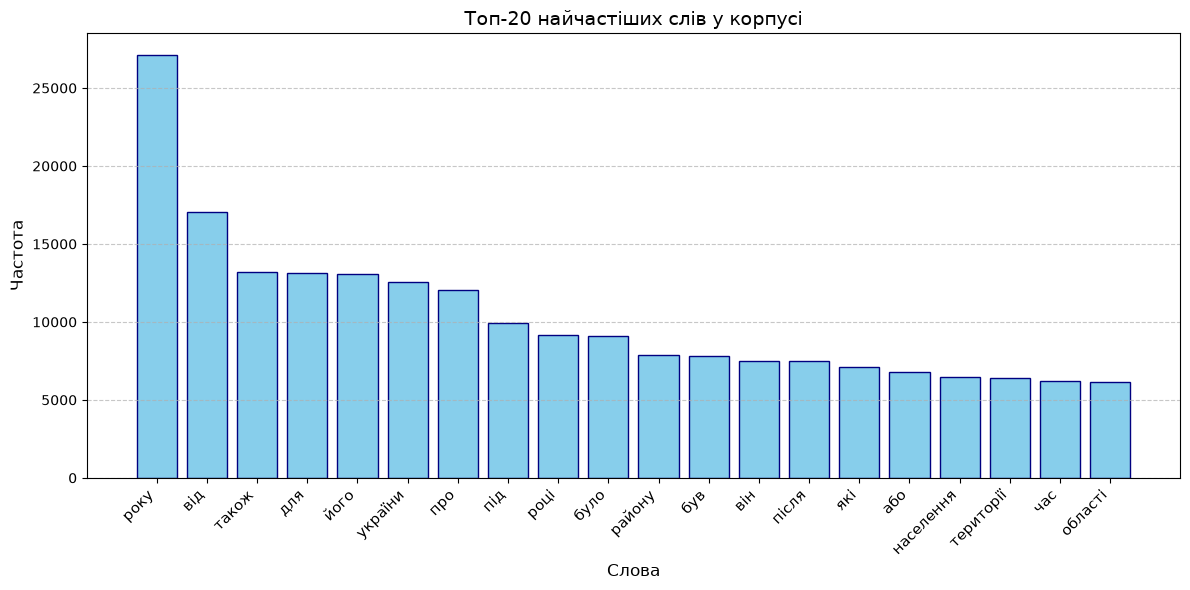

In [6]:
words, counts = zip(*top_20_words)

plt.figure(figsize=(12, 6))
plt.bar(words, counts, color='skyblue', edgecolor='navy')
plt.xlabel('Слова', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.title('Топ-20 найчастіших слів у корпусі', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()